In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob
from datetime import datetime as dt, timedelta
from pathlib import Path

##########
## CURRENTLY AT 20070530
##########


# read in .nc files from angstrom exponent analysis
april_2010_cloud_properties = xr.open_dataset("./data/raw/Cloud_Properties_Daily/20100414-ESACCI-L3U_CLOUD-CLD_PRODUCTS-AVHRR_NOAA-19-fv3.0.nc", engine="netcdf4")
april_2010_cloud_properties

# phase = april_2010_cloud_properties['ctp']
# ice_fraction = (phase == 2).sum(dim=['lat', 'lon']) / \
#     ((phase == 1) | (phase == 2) | (phase == 3)).sum(dim=['lat', 'lon'])

# print(ice_fraction)


<xarray.Dataset> Size: 6GB
Dimensions:                 (time: 1, lat: 3600, lon: 7200)
Coordinates:
  * time                    (time) datetime64[ns] 8B 2010-04-14
  * lat                     (lat) float32 14kB -89.97 -89.93 ... 89.93 89.97
  * lon                     (lon) float32 29kB -180.0 -179.9 ... 179.9 180.0
Data variables: (12/52)
    time_asc                (time, lat, lon) datetime64[ns] 207MB ...
    time_desc               (time, lat, lon) datetime64[ns] 207MB ...
    ctt_asc                 (time, lat, lon) float32 104MB ...
    ctt_asc_unc             (time, lat, lon) float32 104MB ...
    ctt_desc                (time, lat, lon) float32 104MB ...
    ctt_desc_unc            (time, lat, lon) float32 104MB ...
    ...                      ...
    cwp_asc                 (time, lat, lon) float32 104MB ...
    cwp_asc_unc             (time, lat, lon) float32 104MB ...
    cwp_desc                (time, lat, lon) float32 104MB ...
    cwp_desc_unc            (time, lat, lon) float32 104MB ...
    qcflag_asc              (time, lat, lon) float32 104MB ...
    qcflag_desc             (time, lat, lon) float32 104MB ...
Attributes: (12/41)
    CDI:                        Climate Data Interface version 1.8.2 (http://...
    history:                    Tue Nov 27 20:21:15 2018: cdo selname,time_as...
    source:                     AVHRR_NOAA-19_GAC
    institution:                Deutscher Wetterdienst
    Conventions:                CF-1.6,ACDD-1.3
    title:                      ESA Cloud CCI Retrieval Products L3U Output File
    ...                         ...
    comment:                    These data were produced at ESACCI as part of...
    license:                    ESA CCI Data Policy: free and open access
    cdm_data_type:              Grid
    keywords_vocabulary:        GCMD Science Keywords, Version 8.1
    naming_authority:           de.dwd
    CDO:                        Climate Data Operators version 1.8.2 (http://...

In [2]:
print(april_2010_cloud_properties['cph_asc'].attrs)

{'standard_name': 'thermodynamic_phase_of_cloud_water_particles_at_cloud_top', 'long_name': 'cloud phase flag ascending', 'flag_values': array([0, 1, 2], dtype=int8), 'flag_meanings': 'clear liquid ice'}


In [3]:
def get_avhrr_phase_counts(year, month, start_day, end_day, bbox=[-35, 10, 43, 71]):
    """
    Loads daily AVHRR files, stitches them together, and calculates 1x1 phase counts.
    """
    # 1. Search for ALL days in the given month (removed start_day from the string)
    search_pattern = f"./data/raw/Cloud_Properties_Daily/{year}{month:02d}*.nc"
    
    try:
        # 2. open_mfdataset safely stitches all 30 daily files into one timeline
        ds = xr.open_mfdataset(search_pattern, combine='by_coords')
    except Exception as e:
        print(f"File not found matching {search_pattern}. Error: {e}")
        return None

    # 3. CRITICAL FIX: Force latitudes to ascend so the slice(43, 71) doesn't return 0x0
    ds = ds.sortby('lat').sortby('lon')
    
    # Slice the temporal and spatial bounds
    start_date = f"{year}-{month:02d}-{start_day:02d}"
    end_date = f"{year}-{month:02d}-{end_day:02d}"
    
    sliced_ds = ds.sel(
        time=slice(start_date, end_date),
        lat=slice(bbox[2], bbox[3]),
        lon=slice(bbox[0], bbox[1])
    )
    
    # ---------------------------------------------------------
    phase_var = "cph_asc" 
    # temp_var = "ctt_asc"
    flag_liquid = 1
    flag_ice = 2
    # ---------------------------------------------------------
    
    phases = sliced_ds[phase_var]
    
    # Create masks for each phase
    is_liquid = (phases == flag_liquid).astype(int)
    is_ice = (phases == flag_ice).astype(int)
    
    # Sum across the time dimension to get total counts per pixel
    count_liq = is_liquid.sum(dim='time')
    count_ice = is_ice.sum(dim='time')
    
    # Calculate Ice Fraction: Nice / (Nice + Nliquid)
    total_clouds = count_ice + count_liq
    ice_fraction = count_ice / total_clouds.where(total_clouds > 0)
    
    # Coarsen to 1x1 to match MODIS mask
    ice_fraction_1x1 = ice_fraction.coarsen(lat=2, lon=2, boundary='trim').mean()
    
    return ice_fraction_1x1

In [4]:
def plot_cloud_anomaly(data, title):
    plt.figure(figsize=(10, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent([-35, 10, 43, 71], crs=ccrs.PlateCarree())
    
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='dimgray') 
    
    # Diverging colormap for Ice Fraction Anomaly
    # Red = More Ice, Blue = More Liquid
    pcm = ax.pcolormesh(
        data.lon, data.lat, data.values, 
        cmap='RdBu_r', shading='auto', transform=ccrs.PlateCarree(),
        vmin=-0.5, vmax=0.5 
    )
    
    cbar = plt.colorbar(pcm, orientation='vertical', shrink=0.7)
    cbar.set_label('Ice Fraction Anomaly (Δ%)')
    
    plt.title(title, fontsize=14, fontweight='bold')
    plt.show()

# ==========================================
# EXECUTION EXAMPLES
# ==========================================
# Eyjafjallajökull Phase 1 (April)
# analyze_cloud_phase("Eyjafjallajökull", 2010, 4, 14, 18, 9, 23)

# Eyjafjallajökull Phase 2 (May)
# analyze_cloud_phase("Eyjafjallajökull", 2010, 5, 5, 17, 4, 18)

In [5]:
def analyze_daily_cloud_phase(volcano, exp_year, month, day, clim_start_day, clim_end_day, satellite="Aqua"):
    date_str = f"{exp_year}{month:02d}{day:02d}"
    print(f"--- Analyzing Cloud Phase for {volcano}: ({date_str}) ---")
    
    baseline_years = [2007, 2008, 2009, 2012, 2013, 2014]
    baseline_fractions = []
    
    # 1. Calculate Climatological Ice Fraction
    for y in baseline_years:
        frac = get_avhrr_phase_counts(y, month, clim_start_day, clim_end_day)
        if frac is not None:
            baseline_fractions.append(frac)
            
    if not baseline_fractions:
        print("No baseline data found!")
        return
        
    climate_mean_ice_frac = xr.concat(baseline_fractions, dim='year').mean(dim='year', skipna=True)
    
    # 2. Calculate Experimental Ice Fraction
    exp_ice_frac = get_avhrr_phase_counts(exp_year, month, day, day)
    
    # 3. Calculate Anomaly (Experimental - Climatology)
    # Positive value = More ice clouds than normal
    # Negative value = More liquid/mixed clouds than normal
    ice_frac_anomaly = exp_ice_frac - climate_mean_ice_frac
    
    # 4. Apply your previously generated Coarse Bounding Box
    # Ensure this path points to the file you saved at the end of the MODIS script
    mask_path = f"./data/outputs_ttest/{satellite}/{date_str}/data_significant_coarse.nc"
    if os.path.exists(mask_path):
        coarse_mask = xr.open_dataset(mask_path)
        # We only care where the mask is NOT null

        # #######
        # print("AVHRR Coords:", ice_frac_anomaly.lat.values[0:3])
        # print("MODIS Coords:", coarse_mask.lat.values[0:3]) 
        # ######
        
        var_name = list(coarse_mask.data_vars)[0]
        is_ash_plume = coarse_mask[var_name].notnull()

        print("Valid ash pixels today:", is_ash_plume.sum().values)

        aligned_anomaly = ice_frac_anomaly.interp_like(coarse_mask, method='nearest')
        
        # Mask the anomaly data
        # Note: You may need to align coordinates if AVHRR lat/lon grids slightly differ from MODIS
        targeted_anomaly = aligned_anomaly.where(is_ash_plume)
        
        plot_cloud_anomaly(targeted_anomaly, f"{satellite} {volcano}: {date_str} Ice Cloud Fraction Anomaly in Ash Plume")
    else:
        print(f"Warning: Coarse mask not found at {mask_path}.")

--- Analyzing Cloud Phase for Eja: (20100414) ---


Valid ash pixels today: 76


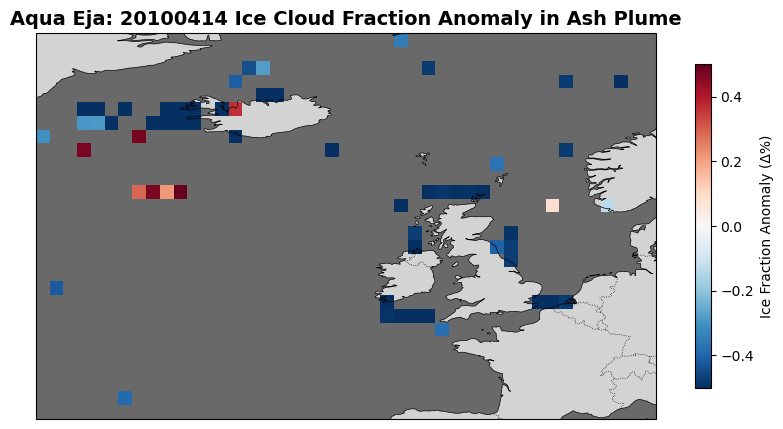

In [6]:
# EXECUTE

analyze_daily_cloud_phase("Eja", 2010, 4, 14, 9, 23)

In [7]:
print(list(april_2010_cloud_properties.data_vars))

['time_asc', 'time_desc', 'ctt_asc', 'ctt_asc_unc', 'ctt_desc', 'ctt_desc_unc', 'ctt_corrected_asc', 'ctt_corrected_asc_unc', 'ctt_corrected_desc', 'ctt_corrected_desc_unc', 'cth_asc', 'cth_asc_unc', 'cth_desc', 'cth_desc_unc', 'cth_corrected_asc', 'cth_corrected_asc_unc', 'cth_corrected_desc', 'cth_corrected_desc_unc', 'ctp_asc', 'ctp_asc_unc', 'ctp_desc', 'ctp_desc_unc', 'ctp_corrected_asc', 'ctp_corrected_asc_unc', 'ctp_corrected_desc', 'ctp_corrected_desc_unc', 'cph_asc', 'cph_desc', 'illum_asc', 'illum_desc', 'stemp_asc', 'stemp_desc', 'stemp_asc_unc', 'stemp_desc_unc', 'cer_asc', 'cer_asc_unc', 'cer_desc', 'cer_desc_unc', 'cot_asc', 'cot_asc_unc', 'cot_desc', 'cot_desc_unc', 'cph_asc_unc', 'cph_desc_unc', 'cph_interim_asc', 'cph_interim_desc', 'cwp_asc', 'cwp_asc_unc', 'cwp_desc', 'cwp_desc_unc', 'qcflag_asc', 'qcflag_desc']


In [8]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import re

def get_avhrr_temp_and_phase(year, month, start_day, end_day, bbox=[-35, 10, 43, 71]):
    """Loads AVHRR data and returns BOTH Temperature and Phase at NATIVE resolution."""
    search_pattern = f"./data/raw/Cloud_Properties_Daily/{year}{month:02d}*.nc"
    
    try:
        ds = xr.open_mfdataset(search_pattern, combine='by_coords')
    except Exception as e:
        print(f"File not found matching {search_pattern}. Error: {e}")
        return None, None

    ds = ds.sortby('lat').sortby('lon')
    
    start_date = f"{year}-{month:02d}-{start_day:02d}"
    end_date = f"{year}-{month:02d}-{end_day:02d}"
    
    sliced_ds = ds.sel(
        time=slice(start_date, end_date),
        lat=slice(bbox[2], bbox[3]),
        lon=slice(bbox[0], bbox[1])
    )
    
    phase_var = "cph_asc" 
    temp_var = "ctt_asc" # Verify this is the correct variable name
    
    return sliced_ds[temp_var], sliced_ds[phase_var]

def analyze_temp_phase_curve(volcano, exp_year, month, day, clim_start, clim_end, satellite="Aqua"):
    date_str = f"{exp_year}{month:02d}{day:02d}"
    print(f"--- Building High-Res Temperature-Phase Curve for {volcano}: ({date_str}) ---")
    
    # 1. Load the MODIS Coarse Mask
    mask_path = f"./data/outputs_ttest/{satellite}/{date_str}/data_significant_coarse.nc"
    if not os.path.exists(mask_path):
        print(f"Warning: Coarse mask not found at {mask_path}.")
        return
        
    coarse_mask = xr.open_dataset(mask_path)
    var_name = list(coarse_mask.data_vars)[0]
    
    # Create the raw mask
    raw_ash_mask = coarse_mask[var_name].notnull().astype(float)

    # 2. Get Experimental Data (Native AVHRR Resolution)
    exp_temp, exp_phase = get_avhrr_temp_and_phase(exp_year, month, day, day)

    if exp_temp is None or exp_phase is None:
        print(f"Skipping {date_str} due to missing or corrupted AVHRR data.")
        return
    
    # Collapse the single time dimension
    exp_temp = exp_temp.mean(dim='time')
    exp_phase = exp_phase.max(dim='time')
    
    # NEW LOGIC: Upsample the mask to match the high-res AVHRR grid
    is_ash_plume = raw_ash_mask.interp_like(exp_temp, method='nearest') == 1.0
    
    # Extract pixels into a 1D list, drop NaNs
    df_exp = pd.DataFrame({
        'temp': exp_temp.where(is_ash_plume).values.flatten(),
        'phase': exp_phase.where(is_ash_plume).values.flatten()
    }).dropna()

    df_exp = df_exp[df_exp['phase'].isin([1,2])]

    # 3. Get Climatology Data (Native AVHRR Resolution)
    baseline_years = [2007, 2008, 2009, 2012, 2013, 2014]
    clim_temps, clim_phases = [], []
    
    for y in baseline_years:
        t, p = get_avhrr_temp_and_phase(y, month, clim_start, clim_end)
        if t is not None:
            clim_temps.append(t)
            clim_phases.append(p)
            
    clim_temp_concat = xr.concat(clim_temps, dim='time')
    clim_phase_concat = xr.concat(clim_phases, dim='time')
    
    ## OLD LOGIC (AVERAGING CLIMATOLOGY INSTEAD OF LISTING)
    # Calculate Mean Temp and Ice Frac without interpolating!
    # clim_mean_temp = clim_temp_concat.mean(dim='time')
    # clim_ice_count = (clim_phase_concat == 2).sum(dim='time')
    # clim_total_count = ((clim_phase_concat == 1) | (clim_phase_concat == 2)).sum(dim='time')
    # clim_ice_frac = clim_ice_count / clim_total_count.where(clim_total_count > 0)

    # # Extract pixels into a 1D list using the upsampled mask
    # df_clim = pd.DataFrame({
    #     'temp': clim_mean_temp.where(is_ash_plume).values.flatten(),
    #     'ice_frac': clim_ice_frac.where(is_ash_plume).values.flatten()
    # }).dropna()

    # 1. Expand the 2D ash mask across the entire 'time' dimension of the 6-year baseline
    # This allows us to mask out every single day individually
    is_ash_plume_3d = is_ash_plume.broadcast_like(clim_temp_concat)

    # 2. Extract every single daily pixel into massive 1D arrays
    clim_temp_flat = clim_temp_concat.where(is_ash_plume_3d).values.flatten()
    clim_phase_flat = clim_phase_concat.where(is_ash_plume_3d).values.flatten()

    # 3. Create the DataFrame and drop NaNs (which removes the pixels outside the mask)
    df_clim = pd.DataFrame({
        'temp': clim_temp_flat,
        'phase': clim_phase_flat
    }).dropna()
    
    # 4. Filter out any undetermined phases, keeping only Liquid (1) and Ice (2)
    df_clim = df_clim[df_clim['phase'].isin([1, 2])]
    
    # 5. Convert phase to a boolean (1 for Ice, 0 for Liquid) so we can average it
    df_clim['is_ice'] = (df_clim['phase'] == 2).astype(int)
    
    # (The pandas .cut() and .groupby() steps later in your script remain exactly the same, 
    # just change `ice_frac` to `is_ice` when grouping df_clim)
    # e.g., clim_curve = df_clim.groupby('temp_bin')['is_ice'].mean()

    # 4. Bin by Temperature (Finer increments since we have more data!)
    bins = np.arange(220, 285, 2.5) 
    bin_centers = bins[:-1] + 1.25
    
    # Calculate Experimental Curve
    df_exp['is_ice'] = (df_exp['phase'] == 2).astype(int)
    df_exp['temp_bin'] = pd.cut(df_exp['temp'], bins=bins, labels=bin_centers)
    
    exp_grouped = df_exp.groupby('temp_bin')['is_ice']
    exp_curve = exp_grouped.mean()
    exp_counts = exp_grouped.count()

    exp_curve = exp_curve.where(exp_counts >= 3) #adjustable threshold, present to avoid wild plot jumps
    
    # Calculate Climatology Curve
    df_clim['temp_bin'] = pd.cut(df_clim['temp'], bins=bins, labels=bin_centers)
    clim_curve = df_clim.groupby('temp_bin')['is_ice'].mean()
    clim_counts = df_clim.groupby('temp_bin')['is_ice'].count()

    # 5. Plotting
    plot_glaciation_curves(bin_centers, exp_curve, exp_counts, clim_curve, clim_counts, f"{satellite} {volcano}: High-Res Glaciation Curve ({date_str})")

def plot_glaciation_curves(temps, exp_data, exp_counts, clim_data, clim_counts, title, savepath="./data/glaciation_plot_outputs/"):
    datestr = re.search(r'\d{8}', title)
    savetitle = f"glaciation_plot_{datestr}.png"
    plt.figure(figsize=(10, 7)) # Slightly larger for better viewing
    
    plt.plot(temps, clim_data, marker='o', linestyle='-', color='gray', linewidth=1.5, label='Climatology (6-Year Baseline)')
    plt.plot(temps, exp_data, marker='s', linestyle='-', color='firebrick', linewidth=2, label='Eruption Day (Inside Ash Plume)')
    
    plt.xlabel('Cloud Top Temperature (K)', fontsize=14)
    plt.ylabel('Ice Cloud Fraction ($N_{ice} / N_{total}$)', fontsize=14)
    plt.title(title, fontsize=16, fontweight='bold')
    
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(fontsize=12)
    
    # Standard meteorological practice: Colder temps on the right (higher altitude)
    plt.gca().invert_xaxis() 
    
    # Add a vertical line for the homogeneous freezing point (~235K)
    plt.axvline(x=235, color='blue', linestyle='--', alpha=0.5, label='Homogeneous Freezing (~235K)')
    
    # Ensure the legend catches the new line
    plt.legend(fontsize=12)
    
    full_save_path = os.path.join(savepath, savetitle)
    # plt.show()
    plt.savefig(full_save_path, bbox_inches='tight', dpi=300)
    plt.close(fig='all')

In [9]:
# analyze_temp_phase_curve("Eja", 2010, 4, 14, 9, 23)

In [10]:
# analyze_temp_phase_curve("Eja", 2010, 4, 18, 9, 23)

In [11]:
# eja_phase1_days = [14, 15, 16, 17, 18]
# eja_phase2_days = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
# grims_days = [21, 22, 23, 24, 25, 26, 27, 28]

# for day in eja_phase1_days:
#     print(f"Plotting Eja Phase 1 day {day}")
#     # analyze_temp_phase_curve("Eja", 2010, 4, day, 9, 23)

# for day in eja_phase2_days:
#     print(f"Plotting Eja Phase 2 day {day}")
#     analyze_temp_phase_curve("Eja", 2010, 5, day, 4, 18)

# for day in grims_days:
#     print(f"Plotting Grimms day {day}")
#     # analyze_temp_phase_curve("Grimms", 2011, 5, day, 17, 31)

In [15]:
def plot_aggregate_glaciation(temps, exp_data, exp_counts, clim_data, clim_counts, title, savetitle, savepath="./data/glaciation_plot_outputs/"):
    fig, ax1 = plt.subplots(figsize=(10, 7))
    
    # ==========================================
    # AXIS 1: The Glaciation Curves (Lines)
    # ==========================================
    ax1.plot(temps, clim_data, marker='o', linestyle='-', color='gray', linewidth=1.5, label='Climatology Baseline', zorder=3)
    ax1.plot(temps, exp_data, marker='s', linestyle='-', color='firebrick', linewidth=2, label='Eruption Phase (Inside Plume)', zorder=3)
    
    ax1.set_xlabel('Cloud Top Temperature (K)', fontsize=14)
    ax1.set_ylabel('Ice Cloud Fraction ($N_{ice} / N_{total}$)', fontsize=14)
    ax1.set_ylim(-0.05, 1.05)
    
    ax1.invert_xaxis() 
    ax1.axvline(x=235, color='blue', linestyle='--', alpha=0.5, label='Homogeneous Freezing (~235K)', zorder=1)
    ax1.grid(True, linestyle=':', alpha=0.7)
    
    # ==========================================
    # AXIS 2: The Sample Counts (Bars)
    # ==========================================
    ax2 = ax1.twinx()
    
    # Only plot the experimental counts
    ax2.bar(temps, exp_counts, width=2.5, alpha=0.25, color='firebrick', label='Plume Pixel Count', zorder=0)
    
    # Color-code the Y-axis to match the red bars
    ax2.set_ylabel('Plume Pixel Count', fontsize=14, color='firebrick')
    ax2.tick_params(axis='y', labelcolor='firebrick')
    
    # Scale the bar height based ONLY on the experimental data
    max_count = exp_counts.max()
    if max_count > 0:
        ax2.set_ylim(0, max_count * 3) 
    
    # ==========================================
    # Formatting & Legends
    # ==========================================
    plt.title(title, fontsize=16, fontweight='bold')
    
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', fontsize=11)
    
    os.makedirs(savepath, exist_ok=True)
    full_save_path = os.path.join(savepath, savetitle)
    plt.savefig(full_save_path, bbox_inches='tight', dpi=300)
    plt.close(fig='all')

In [16]:
def analyze_phase_aggregate(volcano, exp_year, month, days_list, clim_start, clim_end, satellite="Aqua", phase_name="Phase1"):
    print(f"--- Building Aggregate Curve for {volcano} {phase_name} ({satellite}) ---")
    
    all_df_exp = []
    all_df_clim = []

    # 1. PRE-LOAD CLIMATOLOGY (Runs once per phase to save processing time)
    baseline_years = [2007, 2008, 2009, 2012, 2013, 2014]
    clim_temps, clim_phases = [], []
    for y in baseline_years:
        t, p = get_avhrr_temp_and_phase(y, month, clim_start, clim_end)
        if t is not None:
            clim_temps.append(t)
            clim_phases.append(p)
            
    if clim_temps:
        clim_temp_concat = xr.concat(clim_temps, dim='time')
        clim_phase_concat = xr.concat(clim_phases, dim='time')
    else:
        print("Failed to load baseline climatology.")
        return

    # 2. LOOP THROUGH EACH DAY IN THE PHASE
    for day in days_list:
        date_str = f"{exp_year}{month:02d}{day:02d}"
        mask_path = f"./data/outputs_ttest/{satellite}/{date_str}/data_significant_coarse.nc"
        
        if not os.path.exists(mask_path):
            continue
            
        coarse_mask = xr.open_dataset(mask_path)
        var_name = list(coarse_mask.data_vars)[0]
        raw_ash_mask = coarse_mask[var_name].notnull().astype(float)

        exp_temp, exp_phase = get_avhrr_temp_and_phase(exp_year, month, day, day)
        if exp_temp is None or exp_phase is None:
            continue
        
        exp_temp = exp_temp.mean(dim='time')
        exp_phase = exp_phase.max(dim='time')
        
        is_ash_plume = raw_ash_mask.interp_like(exp_temp, method='nearest') == 1.0
        
        # Extract Experimental Data for this specific day
        df_day_exp = pd.DataFrame({
            'temp': exp_temp.where(is_ash_plume).values.flatten(),
            'phase': exp_phase.where(is_ash_plume).values.flatten()
        }).dropna()
        df_day_exp = df_day_exp[df_day_exp['phase'].isin([1,2])]
        all_df_exp.append(df_day_exp)

        # Extract Climatology Data masked by this specific day's footprint
        is_ash_plume_3d = is_ash_plume.broadcast_like(clim_temp_concat)
        df_day_clim = pd.DataFrame({
            'temp': clim_temp_concat.where(is_ash_plume_3d).values.flatten(),
            'phase': clim_phase_concat.where(is_ash_plume_3d).values.flatten()
        }).dropna()
        df_day_clim = df_day_clim[df_day_clim['phase'].isin([1, 2])]
        all_df_clim.append(df_day_clim)

    # 3. POOL ALL DATA TOGETHER
    if not all_df_exp:
        print(f"No valid data found for {phase_name} ({satellite}).")
        return

    df_exp = pd.concat(all_df_exp, ignore_index=True)
    df_clim = pd.concat(all_df_clim, ignore_index=True)

    df_exp['is_ice'] = (df_exp['phase'] == 2).astype(int)
    df_clim['is_ice'] = (df_clim['phase'] == 2).astype(int)

    # 4. BIN AND CALCULATE AGGREGATES
    bins = np.arange(220, 285, 2.5) 
    bin_centers = bins[:-1] + 1.25
    
    df_exp['temp_bin'] = pd.cut(df_exp['temp'], bins=bins, labels=bin_centers)
    exp_grouped = df_exp.groupby('temp_bin')['is_ice']
    exp_curve = exp_grouped.mean()
    exp_counts = exp_grouped.count()
    
    df_clim['temp_bin'] = pd.cut(df_clim['temp'], bins=bins, labels=bin_centers)
    clim_grouped = df_clim.groupby('temp_bin')['is_ice']
    clim_curve = clim_grouped.mean()
    clim_counts = clim_grouped.count()

    # 5. PLOT
    title = f"{satellite} {volcano}: {phase_name} Aggregate Glaciation"
    savetitle = f"{satellite}_{volcano}_{phase_name}_Aggregate.png"
    plot_aggregate_glaciation(bin_centers, exp_curve, exp_counts, clim_curve, clim_counts, title, savetitle)

In [17]:
eja_phase1_days = [14, 15, 16, 17, 18]
eja_phase2_days = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
grims_days = [21, 22, 23, 24, 25, 26, 27, 28]

satellites = ["Aqua", "Terra"]

for sat in satellites:
    # Eja Phase 1
    analyze_phase_aggregate("Eja", 2010, 4, eja_phase1_days, 9, 23, satellite=sat, phase_name="Phase1")
    
    # Eja Phase 2
    analyze_phase_aggregate("Eja", 2010, 5, eja_phase2_days, 4, 18, satellite=sat, phase_name="Phase2")
    
    # Grímsvötn Phase 1
    analyze_phase_aggregate("Grimms", 2011, 5, grims_days, 17, 31, satellite=sat, phase_name=" ")

--- Building Aggregate Curve for Eja Phase1 (Aqua) ---


/tmp/ipykernel_3379856/3678963388.py:77: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  exp_grouped = df_exp.groupby('temp_bin')['is_ice']
/tmp/ipykernel_3379856/3678963388.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clim_grouped = df_clim.groupby('temp_bin')['is_ice']


--- Building Aggregate Curve for Eja Phase2 (Aqua) ---


/tmp/ipykernel_3379856/3678963388.py:77: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  exp_grouped = df_exp.groupby('temp_bin')['is_ice']
/tmp/ipykernel_3379856/3678963388.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clim_grouped = df_clim.groupby('temp_bin')['is_ice']


--- Building Aggregate Curve for Grimms   (Aqua) ---


...

/tmp/ipykernel_3379856/3678963388.py:77: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  exp_grouped = df_exp.groupby('temp_bin')['is_ice']
/tmp/ipykernel_3379856/3678963388.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clim_grouped = df_clim.groupby('temp_bin')['is_ice']


--- Building Aggregate Curve for Eja Phase2 (Terra) ---


/tmp/ipykernel_3379856/3678963388.py:77: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  exp_grouped = df_exp.groupby('temp_bin')['is_ice']
/tmp/ipykernel_3379856/3678963388.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clim_grouped = df_clim.groupby('temp_bin')['is_ice']


--- Building Aggregate Curve for Grimms   (Terra) ---


/tmp/ipykernel_3379856/3678963388.py:77: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  exp_grouped = df_exp.groupby('temp_bin')['is_ice']
/tmp/ipykernel_3379856/3678963388.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clim_grouped = df_clim.groupby('temp_bin')['is_ice']


In [ ]:
# Grab all the daily files
all_files = glob.glob("./data/raw/Cloud_Properties_Daily/*.nc")
bad_files = []

print(f"Scanning {len(all_files)} files for corruption...")

for file_path in all_files:
    try:
        # If it opens, it's healthy. Close it immediately.
        with xr.open_dataset(file_path) as ds:
            pass 
    except Exception as e:
        # If it throws an error, it's corrupted.
        print(f"Deleting corrupted file: {os.path.basename(file_path)}")
        bad_files.append(file_path)
        os.remove(file_path)

print(f"\nScan complete. Deleted {len(bad_files)} poisoned files.")

Scanning 486 files for corruption...


Deleting corrupted file: 20100501-ESACCI-L3U_CLOUD-CLD_PRODUCTS-AVHRR_NOAA-19-fv3.0.nc
Deleting corrupted file: 20120421-ESACCI-L3U_CLOUD-CLD_PRODUCTS-AVHRR_NOAA-19-fv3.0.nc

Scan complete. Deleted 2 poisoned files.
